<a href="https://colab.research.google.com/github/dimasrhesky270206/Pcvk_SEMESTER-5/blob/main/pertemuan_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TUGAS PRATIKUM

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

3. Buatlah fungsi dilasi serta tampilkan hasil dilasi pada citra dengan Structuring Element
Dilasi (SED) berbentuk cross 3 x 3 tanpa menggunakan library morphology dari
openCV,

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


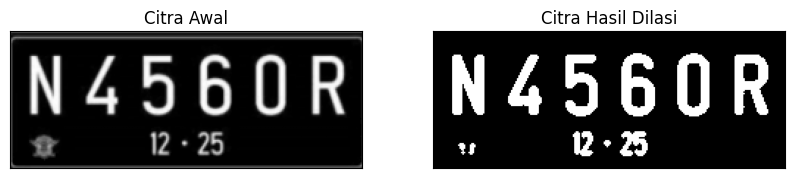

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

def dilasi_citra(F):
    # ukuran citra
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # SED cross 3x3
    SED = np.array([[0, 1, 0],
                    [1, 1, 1],
                    [0, 1, 0]], dtype=np.uint8)
    constant1 = (SED.shape[0] - 1) // 2   # = 1

    # padding nol agar piksel tepi ikut diproses
    Fp = np.pad(F, constant1, mode='constant', constant_values=0)

    # proses dilasi
    for i in range(p):
        for j in range(q):
            temp = Fp[i:i + 3, j:j + 3]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD

img_d = cv2.imread('/content/drive/MyDrive/pcvk/plat nomer.jpg', 0)
if img_d is None:
    raise ValueError("Gambar tidak ditemukan, cek kembali path-nya.")

ret, thresh = cv2.threshold(img_d, 125, 255, cv2.THRESH_BINARY)
imgD = dilasi_citra(thresh)

plt.figure(figsize=(10, 4))
plt.subplot(121), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

4. Buatlah program implementasi operasi dilasi Structuring Element Dilasi (SED)
berbentuk cross 3 x 3 dengan menggunakan library morphology dari openCV,

[[1 1 1]
 [1 1 1]
 [1 1 1]]


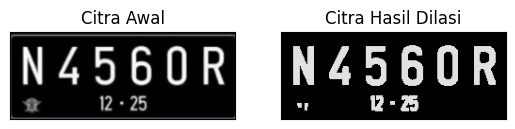

In [ ]:
img = cv2.imread('/content/drive/MyDrive/pcvk/plat nomer.jpg')
#img = cv2.imread('morp.jpg',0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3),np.uint16)
dilasi = cv2.dilate(thresh,kernel,iterations = 1)
print(kernel)
plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(dilasi),plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])
plt.show()

5. Buatlah fungsi erosi serta tampilkan hasil erosi pada citra dengan Structuring Element
Erosi (SE) berbentuk square 5 x 5 tanpa menggunakan library morphology dari
openCV,

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


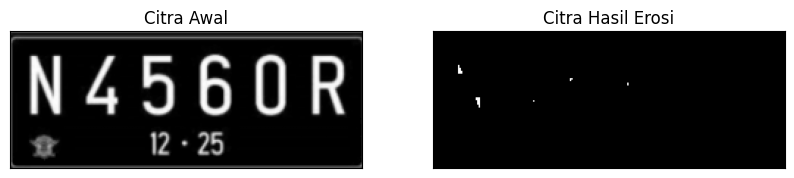

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

# Erosi tanpa library
def erosi_citra(F, k):
    # size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    # padding 255 agar piksel tepi ikut diproses
    Fp = np.pad(F, constant, mode='constant', constant_values=255)

    # Proses erosi
    for i in range(m):
        for j in range(n):
            temp = Fp[i:i + k, j:j + k]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE

img_e = cv2.imread('/content/drive/MyDrive/pcvk/plat nomer.jpg', 0)
if img_e is None:
    raise ValueError("Gambar tidak ditemukan, cek kembali path-nya.")

ret1, thresh1 = cv2.threshold(img_e, 175, 255, cv2.THRESH_BINARY)

k = 5
imgE = erosi_citra(thresh1, k)

plt.figure(figsize=(10, 4))
plt.subplot(121), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

6. Buatlah program implementasi operasi dilasi Structuring Element Erosi (SE) berbentuk
square 5 x 5 dengan menggunakan library morphology dari openCV,

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


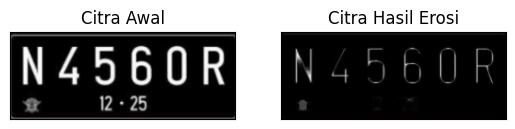

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

# EROSI LIBRARY (tanpa threshold)
img = cv2.imread('/content/drive/MyDrive/pcvk/plat nomer.jpg')
if img is None:
    raise ValueError("Gambar tidak ditemukan, cek kembali path-nya.")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

kernel = np.ones((5, 5), np.uint8)
erosion = cv2.erode(img, kernel, iterations=1)

plt.subplot(121), plt.imshow(img), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(erosion), plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])
plt.show()

7. Buatlah program implementasi operasi opening dengan Structuring Element
berbentuk square 3 x 3 tanpa dan dengan menggunakan library morphology dari
openCV,

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


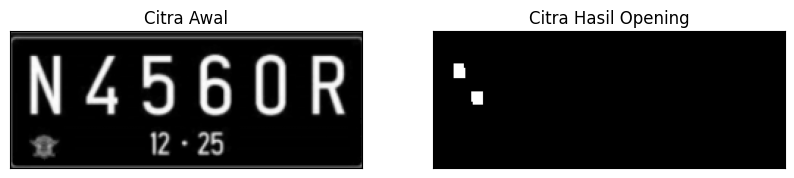

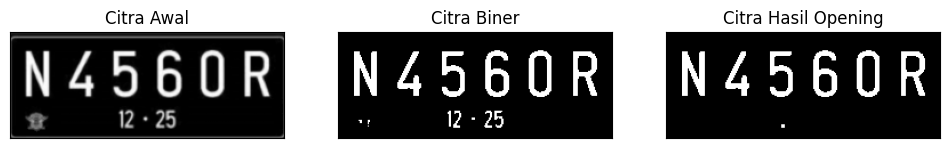

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

# ---------- Fungsi morfologi tanpa library (SE square k x k) ----------
def erosi_citra(F, k):
    m, n = F.shape
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)
    Fp = np.pad(F, constant, mode='constant', constant_values=255)
    for i in range(m):
        for j in range(n):
            imgE[i, j] = np.min(Fp[i:i + k, j:j + k] * SE)
    return imgE

def dilasi_citra(F, k):
    p, q = F.shape
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2
    imgD = np.zeros((p, q), dtype=np.uint8)
    Fp = np.pad(F, constant, mode='constant', constant_values=0)
    for i in range(p):
        for j in range(q):
            imgD[i, j] = np.max(Fp[i:i + k, j:j + k] * SE)
    return imgD

# Sesuaikan path dengan folder di Drive-mu (PCVK atau pcvk)
path = '/content/drive/MyDrive/pcvk/plat nomer.jpg'

# ================= Opening TANPA library morphology =================
img_o = cv2.imread(path, 0)
if img_o is None:
    raise ValueError("Gambar tidak ditemukan, cek kembali path-nya.")
reto, thresho = cv2.threshold(img_o, 127, 255, cv2.THRESH_BINARY)

k_manual = 7   # sesuai gambar hasil di jobsheet; ganti 3 jika mengikuti teks soal
imgO = dilasi_citra(erosi_citra(thresho, k_manual), k_manual)

plt.figure(figsize=(10, 4))
plt.subplot(121), plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

# ================= Opening DENGAN library morphology =================
img = cv2.imread(path, 0)
ret, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(openn, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

8.Buatlah program implementasi operasi closing dengan Structuring Element berbentuk
square 3 x 3 tanpa dan dengan menggunakan library morphology dari openCV,

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


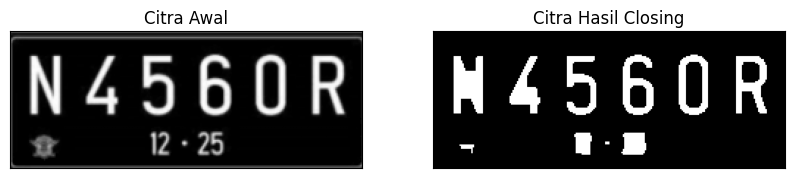

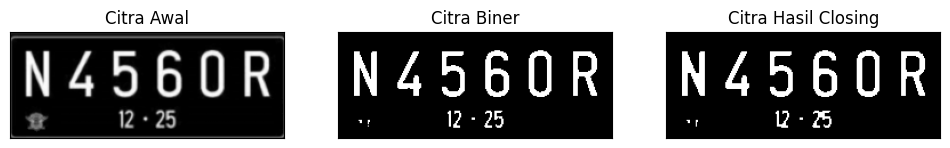

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

# ---------- Fungsi morfologi tanpa library (SE square k x k) ----------
def erosi_citra(F, k):
    m, n = F.shape
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)
    Fp = np.pad(F, constant, mode='constant', constant_values=255)
    for i in range(m):
        for j in range(n):
            imgE[i, j] = np.min(Fp[i:i + k, j:j + k] * SE)
    return imgE

def dilasi_citra(F, k):
    p, q = F.shape
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2
    imgD = np.zeros((p, q), dtype=np.uint8)
    Fp = np.pad(F, constant, mode='constant', constant_values=0)
    for i in range(p):
        for j in range(q):
            imgD[i, j] = np.max(Fp[i:i + k, j:j + k] * SE)
    return imgD

# Sesuaikan path dengan folder di Drive-mu (PCVK atau pcvk)
path = '/content/drive/MyDrive/pcvk/plat nomer.jpg'

# ================= Closing TANPA library morphology =================
img_c = cv2.imread(path, 0)
if img_c is None:
    raise ValueError("Gambar tidak ditemukan, cek kembali path-nya.")
retc, threshc = cv2.threshold(img_c, 127, 255, cv2.THRESH_BINARY)

k_manual = 7   # mengikuti contoh jobsheet; ganti 3 jika mengikuti teks soal
imgC = erosi_citra(dilasi_citra(threshc, k_manual), k_manual)

plt.figure(figsize=(10, 4))
plt.subplot(121), plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgC, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

# ================= Closing DENGAN library morphology =================
img = cv2.imread(path, 0)
ret, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(closs, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

9. Buatlah program implementasi operasi dilasi dengan Structuring Element berbentuk
Cross 3 x 3 dan 5 x 5,

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
SED = Cross 3


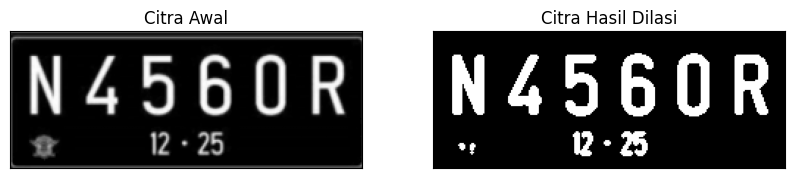

SED = Cross 5


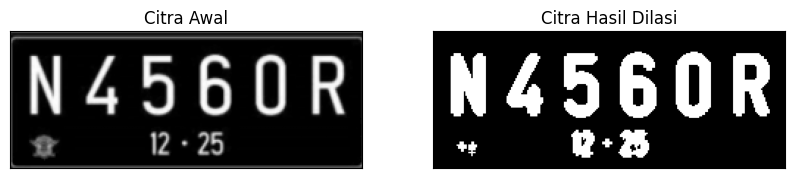

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

# Dilasi dengan SED berbentuk cross w x w
def dilasi_citra(F, w):
    # size image
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED) cross
    SED = np.zeros((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2
    SED[constant1, :] = 1   # baris tengah
    SED[:, constant1] = 1   # kolom tengah

    # padding nol agar piksel tepi ikut diproses
    Fp = np.pad(F, constant1, mode='constant', constant_values=0)

    # Proses dilasi
    for i in range(p):
        for j in range(q):
            temp = Fp[i:i + w, j:j + w]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD

# Baca citra dan threshold
img_d = cv2.imread('/content/drive/MyDrive/pcvk/plat nomer.jpg', 0)
if img_d is None:
    raise ValueError("Gambar tidak ditemukan, cek kembali path-nya.")
ret, thresh = cv2.threshold(img_d, 127, 255, cv2.THRESH_BINARY)

# ---------- SED = Cross 3 x 3 ----------
print('SED = Cross 3')
w = 3
imgD3 = dilasi_citra(thresh, w)

plt.figure(figsize=(10, 4))
plt.subplot(121), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgD3, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

# ---------- SED = Cross 5 x 5 ----------
print('SED = Cross 5')
w = 5
imgD5 = dilasi_citra(thresh, w)

plt.figure(figsize=(10, 4))
plt.subplot(121), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgD5, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

10. Buatlah program implementasi operasi dilasi dengan Structuring Element berbentuk
Circular 3 x 3 dan 5 x 5,

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
SED = Circle 3


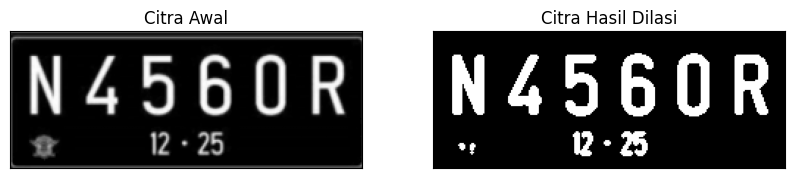

SED = Circle 5


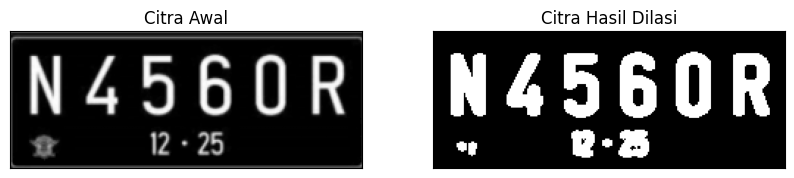

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

# Dilasi dengan SED berbentuk circular (ellipse) w x w
def dilasi_citra(F, w):
    # size image
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED) circular
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2

    # padding nol agar piksel tepi ikut diproses
    Fp = np.pad(F, constant1, mode='constant', constant_values=0)

    # Proses dilasi
    for i in range(p):
        for j in range(q):
            temp = Fp[i:i + w, j:j + w]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD

# Baca citra dan threshold (cukup sekali)
img_d = cv2.imread('/content/drive/MyDrive/pcvk/plat nomer.jpg', 0)
if img_d is None:
    raise ValueError("Gambar tidak ditemukan, cek kembali path-nya.")
ret, thresh = cv2.threshold(img_d, 127, 255, cv2.THRESH_BINARY)

# ---------- SED = Circle 3 ----------
print('SED = Circle 3')
imgD3 = dilasi_citra(thresh, 3)

plt.figure(figsize=(10, 4))
plt.subplot(121), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgD3, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

# ---------- SED = Circle 5 ----------
print('SED = Circle 5')
imgD5 = dilasi_citra(thresh, 5)

plt.figure(figsize=(10, 4))
plt.subplot(121), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgD5, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

11. Buatlah program implementasi operasi erosi dengan Structuring Element berbentuk
Rectangle 3 x 5 dan 5 x 7

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
SE = Rectangle 3x5


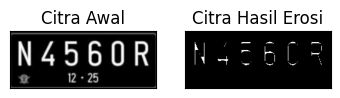

SE = Rectangle 5x7


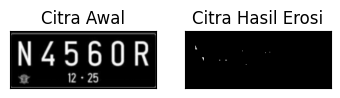

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')


# Erosi dengan Structuring Element Rectangle
def erosi_citra(F, p, l):
    # Ukuran citra
    m, n = F.shape

    # Generate Structuring Element (SE) persegi panjang
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))

    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2

    # Menyiapkan citra hasil
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses erosi
    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[
                i - constant1:i + constant1 + 1,
                j - constant2:j + constant2 + 1
            ]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE


# =======================
# SE Rectangle 3x5
# =======================
print("SE = Rectangle 3x5")

img_e = cv2.imread('/content/drive/MyDrive/pcvk/plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

p = 5
l = 3

imgE = erosi_citra(thresh1, p, l)

plt.subplot(131)
plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

plt.subplot(132)
plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi')
plt.xticks([])
plt.yticks([])

plt.show()


# =======================
# SE Rectangle 5x7
# =======================
print("SE = Rectangle 5x7")

img_e = cv2.imread('/content/drive/MyDrive/pcvk/plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

p = 7
l = 5

imgE = erosi_citra(thresh1, p, l)

plt.subplot(131)
plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

plt.subplot(132)
plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi')
plt.xticks([])
plt.yticks([])

plt.show()

12. Buatlah program implementasi operasi erosi dengan Structuring Element berbentuk
Line Vertikal 3 dan 5

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
SE = Line Vertikal 3


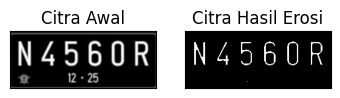

SE = Line Vertikal 5


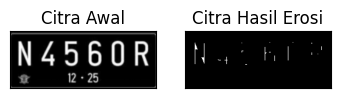

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

# Erosi Line Vertikal SE
def erosi_citra(F, k):
    # Ukuran citra
    m, n = F.shape

    # Generate Structuring Element (SE) Line Vertikal
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k))

    constant = (k - 1) // 2

    # Menyiapkan citra hasil
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[
                i - constant:i + constant + 1,
                j - constant:j + constant + 1
            ]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE


# =========================
# SE Line Vertikal 3
# =========================
print('SE = Line Vertikal 3')

img_e = cv2.imread(
    '/content/drive/MyDrive/pcvk/plat nomer.jpg', 0
)

ret1, thresh1 = cv2.threshold(
    img_e, 127, 225, cv2.THRESH_BINARY
)

k = 3
imgE = erosi_citra(thresh1, k)

plt.subplot(131)
plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

plt.subplot(132)
plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi')
plt.xticks([])
plt.yticks([])

plt.show()


# =========================
# SE Line Vertikal 5
# =========================
print('SE = Line Vertikal 5')

img_e = cv2.imread(
    '/content/drive/MyDrive/pcvk/plat nomer.jpg', 0
)

ret1, thresh1 = cv2.threshold(
    img_e, 127, 225, cv2.THRESH_BINARY
)

k = 5
imgE = erosi_citra(thresh1, k)

plt.subplot(131)
plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

plt.subplot(132)
plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi')
plt.xticks([])
plt.yticks([])

plt.show()

13 TopHat


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


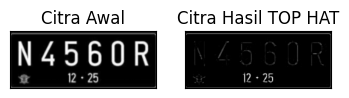

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')


# Getting the kernel to be used in Top-Hat
filterSize = (3, 3)
kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    filterSize
)

# Reading the image
img = cv2.imread(
    '/content/drive/MyDrive/pcvk/plat nomer.jpg'
)

img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Top-Hat operation
tophat_img = cv2.morphologyEx(
    img,
    cv2.MORPH_TOPHAT,
    kernel
)

# Displaying the original and Top-Hat images
plt.subplot(131)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

plt.subplot(132)
plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil TOP HAT')
plt.xticks([])
plt.yticks([])

plt.show()

14 BLACKHAT

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


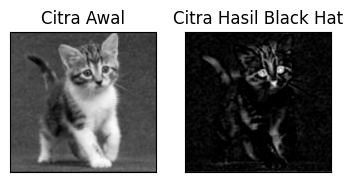

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)
# Reading the image named 'input.jpg'
img = cv2.imread('/content/drive/MyDrive/pcvk/kittens.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
# Applying the Black-Hat operation
#tophat_img = cv2.morphologyEx(img,cv2.MORPH_BLACKHAT, kernel)
Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)
#cv2.imshow("original", input_image)
#cv2.imshow("tophat", tophat_img)
#cv2.waitKey(5000)
plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(blackhat,cmap = 'gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()


15. Skeleton

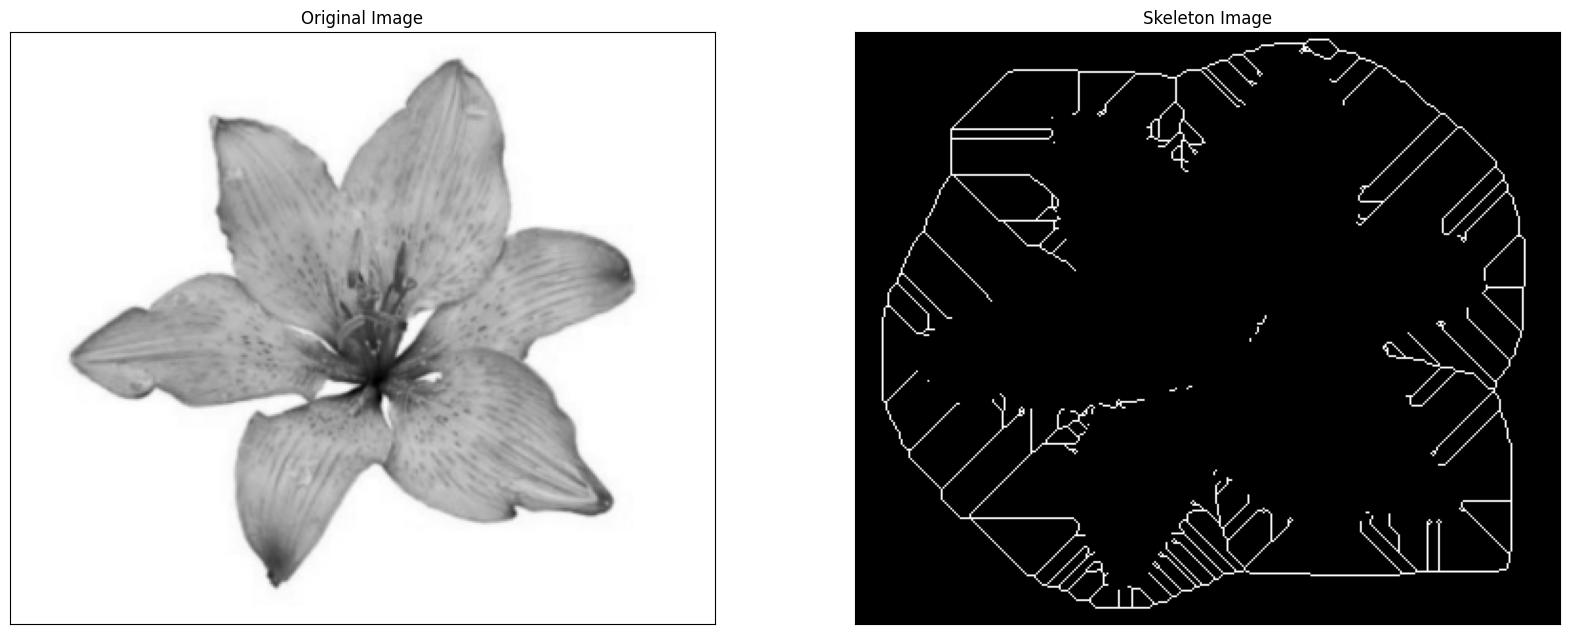

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# Read image
img = cv2.imread('/content/drive/MyDrive/pcvk/Lily.jpg', 0)

# Check image
if img is None:
    print("Gambar tidak ditemukan. Periksa kembali lokasi file.")
else:
    # Convert image to binary
    binary = img > filters.threshold_triangle(img)

    # True to 1 and False to 0
    binary_cp = binary.copy()
    binary_cp[binary_cp == True] = 1
    binary_cp[binary_cp == False] = 0

    # Skeletonize image
    skeleton = skeletonize(binary_cp)

    # Print images
    plt.figure(figsize=(20, 20))

    plt.subplot(121)
    plt.imshow(img, cmap='gray')
    plt.title('Original Image')
    plt.xticks([])
    plt.yticks([])

    plt.subplot(122)
    plt.imshow(skeleton, cmap='gray')
    plt.title('Skeleton Image')
    plt.xticks([])
    plt.yticks([])

    plt.savefig('binary_and_bin_skeleton.png')
    plt.show()

16. Skeleton Inverse

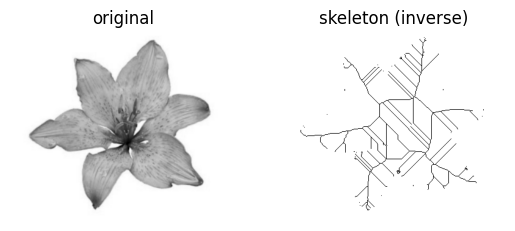

In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# Read image
img = cv2.imread('/content/drive/MyDrive/pcvk/Lily.jpg', 0)

# Note: we want the black bits to be True, so use <
binary = img < filters.threshold_triangle(img)
# skeletonize image
skeleton = skeletonize(binary)

# print images
fig, ax = plt.subplots(1, 2)
ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()

# note the reversed colormap, gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()
plt.show()

17. Thickening

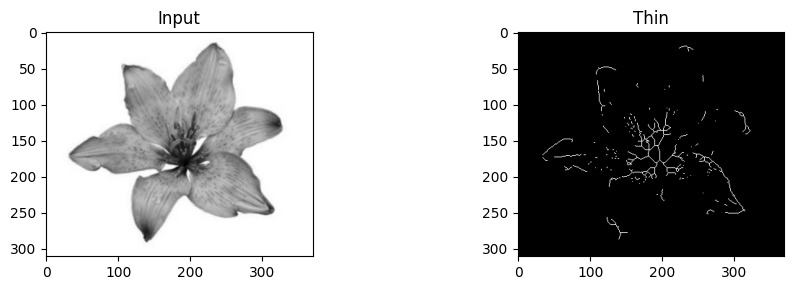

In [19]:
from skimage import img_as_float, io, color, morphology
import matplotlib.pyplot as plt

# Membaca citra
img = io.imread('/content/drive/MyDrive/pcvk/Lily.jpg')

# Mengubah citra menjadi grayscale
if img.ndim == 3:
    image = color.rgb2gray(img[:, :, :3])
else:
    image = img

# Mengubah nilai piksel menjadi float
image = img_as_float(image)

# Mengubah citra menjadi biner
image_binary = image < 0.5

# Proses Thin
out_thin = morphology.thin(image_binary)

# Menampilkan citra Input dan hasil Thin
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))

ax0.imshow(image, cmap='gray')
ax0.set_title('Input')
ax0.axis('on')

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')
ax1.axis('on')

plt.tight_layout()
plt.savefig('/tmp/char_out.png')
plt.show()

E. Tugas Praktikum

1. Import library dan membaca citra KTP

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


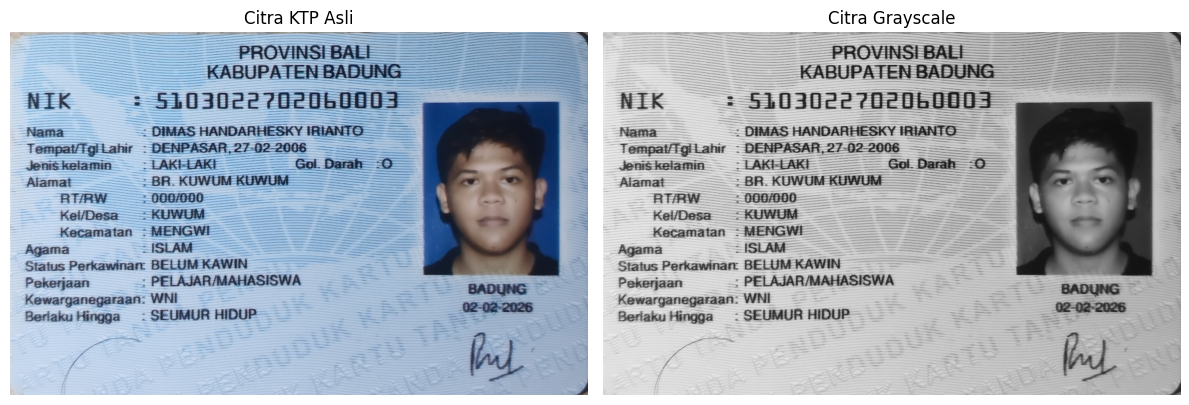

In [20]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

# Membaca citra KTP
path = '//content/drive/MyDrive/pcvk/KTPdimas.jpg'
img = cv2.imread(path)

if img is None:
    raise FileNotFoundError(
        'Citra KTP tidak ditemukan. Periksa kembali path gambar.'
    )

# Mengubah citra menjadi grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Menampilkan citra asli dan grayscale
plt.figure(figsize=(12, 5))

plt.subplot(121)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Citra KTP Asli')
plt.axis('off')

plt.subplot(122)
plt.imshow(gray, cmap='gray')
plt.title('Citra Grayscale')
plt.axis('off')

plt.tight_layout()
plt.show()

2. Thresholding citra


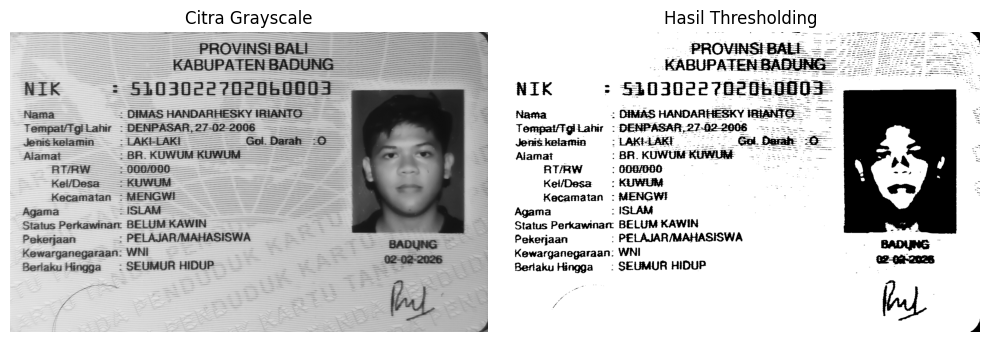

In [21]:
# Thresholding Otsu
ret, binary = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Menampilkan hasil thresholding
plt.figure(figsize=(10, 5))

plt.subplot(121)
plt.imshow(gray, cmap='gray')
plt.title('Citra Grayscale')
plt.axis('off')

plt.subplot(122)
plt.imshow(binary, cmap='gray')
plt.title('Hasil Thresholding')
plt.axis('off')

plt.tight_layout()
plt.show()

3. Operasi morfologi

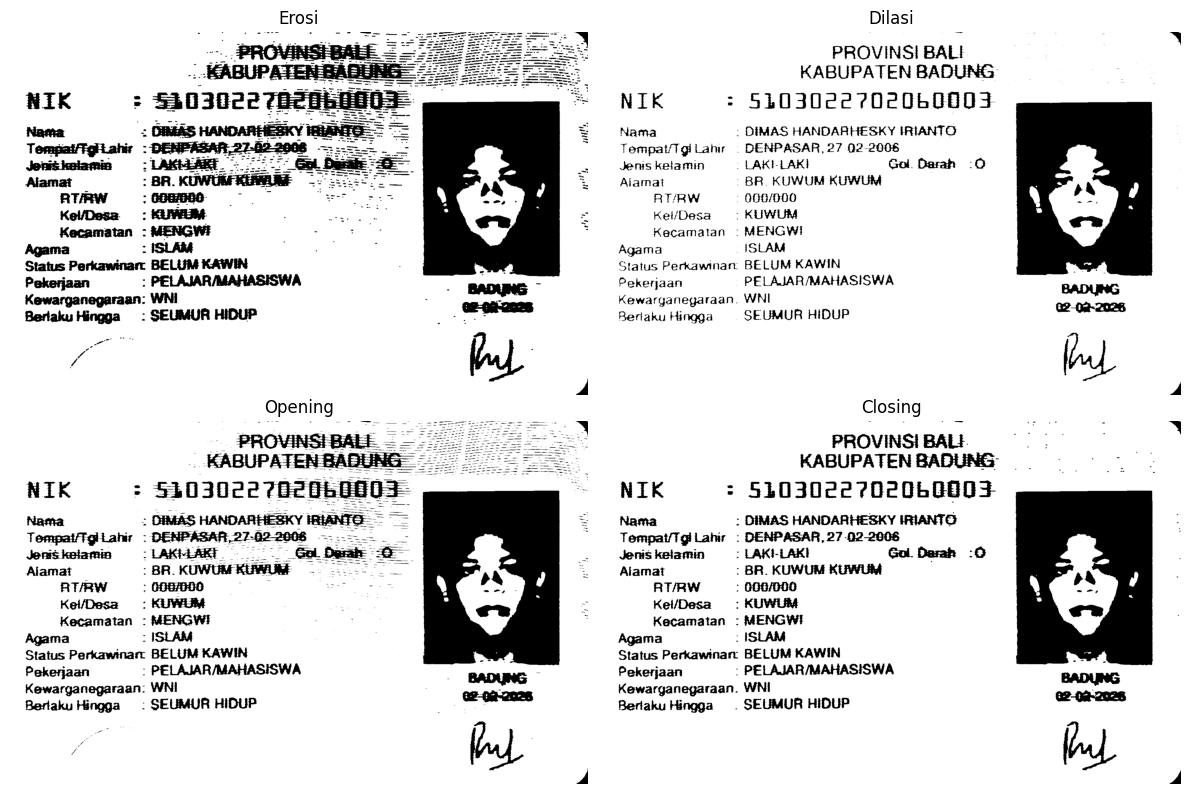

In [22]:
# Membuat Structuring Element
kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT, (3, 3)
)

# Proses erosi
erosi = cv2.erode(binary, kernel, iterations=1)

# Proses dilasi
dilasi = cv2.dilate(binary, kernel, iterations=1)

# Proses opening
opening = cv2.morphologyEx(
    binary, cv2.MORPH_OPEN, kernel
)

# Proses closing
closing = cv2.morphologyEx(
    binary, cv2.MORPH_CLOSE, kernel
)

# Menampilkan hasil operasi morfologi
plt.figure(figsize=(12, 8))

plt.subplot(221)
plt.imshow(erosi, cmap='gray')
plt.title('Erosi')
plt.axis('off')

plt.subplot(222)
plt.imshow(dilasi, cmap='gray')
plt.title('Dilasi')
plt.axis('off')

plt.subplot(223)
plt.imshow(opening, cmap='gray')
plt.title('Opening')
plt.axis('off')

plt.subplot(224)
plt.imshow(closing, cmap='gray')
plt.title('Closing')
plt.axis('off')

plt.tight_layout()
plt.show()

4. Membandingkan hasil akhir

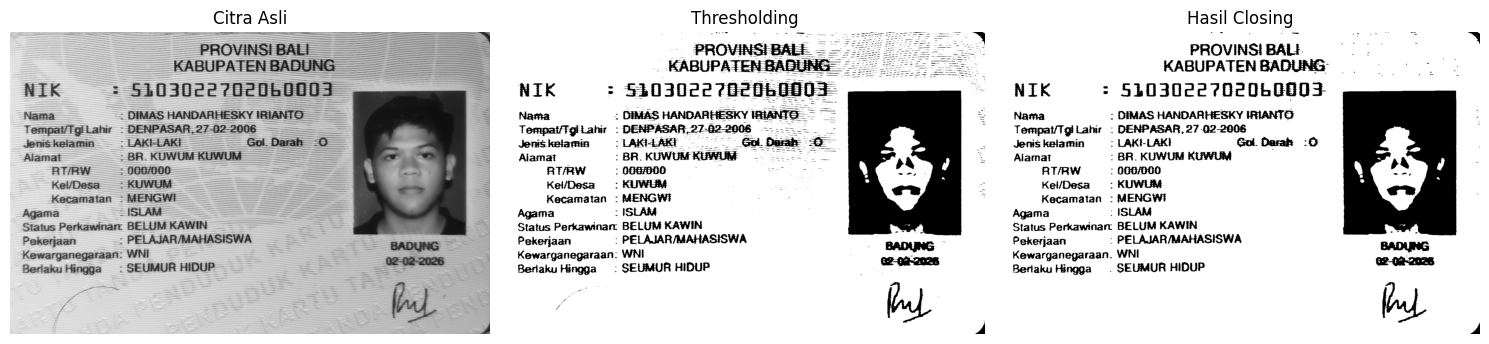

Hasil tersimpan: /content/drive/MyDrive/pcvk/KTPdimas.jpg


In [24]:
# Menampilkan perbandingan hasil
plt.figure(figsize=(15, 5))

plt.subplot(131)
plt.imshow(gray, cmap='gray')
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(132)
plt.imshow(binary, cmap='gray')
plt.title('Thresholding')
plt.axis('off')

plt.subplot(133)
plt.imshow(closing, cmap='gray')
plt.title('Hasil Closing')
plt.axis('off')

plt.tight_layout()
plt.show()

# Menyimpan hasil pemrosesan
cv2.imwrite('/content/drive/MyDrive/pcvk/KTPdimas.jpg', closing)

print('Hasil tersimpan: /content/drive/MyDrive/pcvk/KTPdimas.jpg')